# PowerGuard — Classification (с поправен leakage)

**Цел:** Обучение на 6 класификатора за откриване на аномалии.

**ВАЖНО:** Премахнахме leakage features (`P`, `P_over_U`, `apparent_power`, `Q_over_P`, `dP_dt`).

Причина: `P` директно кодира отговора — всяка аномалия променя мощността по различен начин. Моделът не учи физиката, а просто чете P. Това е **target leakage**.

**Модели:**
1. Logistic Regression (baseline)
2. Decision Tree (baseline)
3. Random Forest (ensemble)
4. SVM (kernel)
5. XGBoost ⭐
6. LightGBM ⭐

**Метрики:** AUC-PR (imbalanced), F1, Precision, Recall, ROC-AUC

**Split:** Time-based (не random!)

In [1]:
# ═══════════════════════════════════════════════════════
# IMPORTS
# ═══════════════════════════════════════════════════════
import sys
import time
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, classification_report,
    roc_curve, precision_recall_curve,
)
from sklearn.model_selection import TimeSeriesSplit

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from src.powerguard.config import SYNTHETIC_DATA_FILE, FIGURES_DIR, RANDOM_SEED
from src.powerguard.data.features import build_features

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

print("Imports OK")

Imports OK


## 1. Load Data + Премахване на leakage features

**Leakage features** са тези, които директно съдържат информация за target. В нашия случай `P` е такъв — всяка аномалия променя мощността по уникален начин, така че моделът просто чете P.

In [2]:
# Зареждане
df = pd.read_parquet(SYNTHETIC_DATA_FILE)
features = build_features(df)
y = df["is_anomaly"].values

print(f"Data shape: {df.shape}")
print(f"Features shape (before leak removal): {features.shape}")
print(f"Target shape: {y.shape}")
print(f"Anomaly ratio: {y.mean():.4f}")

# ═══════════════════════════════════════════════════════
# ПРЕМАХНИ LEAKAGE FEATURES
# ═══════════════════════════════════════════════════════
# P директно кодира отговора — всяка аномалия променя P по уникален начин
# Производните на P също имат leakage
LEAKY_FEATURES = [
    'P',               # директно кодира аномалията
    'P_over_U',        # = I * cos_phi — производна на P
    'Q_over_P',        # производна на P
    'apparent_power',  # = sqrt(P²+Q²)
    'dP_dt',           # производна на P
]

features = features.drop(columns=LEAKY_FEATURES, errors='ignore')

print(f"\nFeatures shape (after leak removal): {features.shape}")
print(f"Removed features: {LEAKY_FEATURES}")
print(f"\nОстанали features ({len(features.columns)}):")
for i, col in enumerate(features.columns, 1):
    print(f"  {i:2d}. {col}")

Data shape: (105000, 12)
Features shape (before leak removal): (105000, 31)
Target shape: (105000,)
Anomaly ratio: 0.0476

Features shape (after leak removal): (105000, 26)
Removed features: ['P', 'P_over_U', 'Q_over_P', 'apparent_power', 'dP_dt']

Останали features (26):
   1. U
   2. I
   3. Q
   4. T
   5. f
   6. R_calc
   7. cos_phi_calc
   8. ohm_residual
   9. power_residual
  10. power_loss
  11. efficiency
  12. freq_deviation
  13. T_over_I
  14. T_deviation
  15. dU_dt
  16. dI_dt
  17. dT_dt
  18. I_over_U
  19. U_rolling_std_10
  20. U_rolling_mean_10
  21. I_rolling_std_10
  22. I_rolling_mean_10
  23. T_rolling_std_10
  24. T_rolling_mean_10
  25. ohm_residual_rolling_std_10
  26. ohm_residual_rolling_mean_10


In [3]:
# Time-based split (НЕ random!)
split_idx = int(0.8 * len(features))

X_train = features.iloc[:split_idx].reset_index(drop=True)
X_test = features.iloc[split_idx:].reset_index(drop=True)
y_train = y[:split_idx]
y_test = y[split_idx:]

print(f"Train: {X_train.shape} — anomaly ratio: {y_train.mean():.4f}")
print(f"Test:  {X_test.shape} — anomaly ratio: {y_test.mean():.4f}")

# Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nScaling OK")

Train: (84000, 26) — anomaly ratio: 0.0476
Test:  (21000, 26) — anomaly ratio: 0.0476

Scaling OK


## 2. Train All Classifiers

In [4]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight = {scale_pos_weight:.2f}")

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=RANDOM_SEED
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10, class_weight="balanced", random_state=RANDOM_SEED
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=15, class_weight="balanced",
        random_state=RANDOM_SEED, n_jobs=-1
    ),
    "SVM": SVC(
        kernel="rbf", C=1.0, gamma="scale",
        probability=True, class_weight="balanced", random_state=RANDOM_SEED
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200, max_depth=6, learning_rate=0.1,
        scale_pos_weight=scale_pos_weight,
        eval_metric="aucpr", random_state=RANDOM_SEED, n_jobs=-1
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=200, max_depth=-1, learning_rate=0.1,
        class_weight="balanced", random_state=RANDOM_SEED, n_jobs=-1,
        verbose=-1
    ),
}

print(f"\nДефинирани {len(models)} модела:")
for name in models:
    print(f"  - {name}")

scale_pos_weight = 19.99

Дефинирани 6 модела:
  - Logistic Regression
  - Decision Tree
  - Random Forest
  - SVM
  - XGBoost
  - LightGBM


In [5]:
results = {}

for name, model in models.items():
    print(f"\n{'='*60}")
    print(f"Training: {name}")
    print(f"{'='*60}")
    
    t0 = time.time()
    model.fit(X_train_scaled, y_train)
    train_time = time.time() - t0
    
    t0 = time.time()
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    predict_time = time.time() - t0
    
    metrics = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "AUC-PR": average_precision_score(y_test, y_prob),
        "Train time (s)": train_time,
        "Predict time (s)": predict_time,
    }
    results[name] = metrics
    
    print(f"  F1:      {metrics['F1']:.4f}")
    print(f"  AUC-PR:  {metrics['AUC-PR']:.4f}")
    print(f"  Recall:  {metrics['Recall']:.4f}")
    print(f"  Time:    {train_time:.2f}s train, {predict_time:.3f}s predict")


Training: Logistic Regression
  F1:      1.0000
  AUC-PR:  1.0000
  Recall:  1.0000
  Time:    0.06s train, 0.001s predict

Training: Decision Tree
  F1:      1.0000
  AUC-PR:  1.0000
  Recall:  1.0000
  Time:    0.34s train, 0.002s predict

Training: Random Forest
  F1:      1.0000
  AUC-PR:  1.0000
  Recall:  1.0000
  Time:    0.64s train, 0.055s predict

Training: SVM
  F1:      1.0000
  AUC-PR:  1.0000
  Recall:  1.0000
  Time:    4.57s train, 0.479s predict

Training: XGBoost
  F1:      1.0000
  AUC-PR:  1.0000
  Recall:  1.0000
  Time:    0.37s train, 0.005s predict

Training: LightGBM
  F1:      1.0000
  AUC-PR:  1.0000
  Recall:  1.0000
  Time:    0.23s train, 0.025s predict


## 3. Results Comparison

In [6]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values("AUC-PR", ascending=False)

print("\n" + "="*80)
print("РЕЗУЛТАТИ (сортирани по AUC-PR)")
print("="*80)
print(results_df.to_string())

results_df.to_csv(PROJECT_ROOT / "results" / "02_classifier_results.csv")
print(f"\nЗапазено в results/02_classifier_results.csv")


РЕЗУЛТАТИ (сортирани по AUC-PR)
                     Accuracy  Precision  Recall   F1  ROC-AUC  AUC-PR  Train time (s)  Predict time (s)
Logistic Regression       1.0        1.0     1.0  1.0      1.0     1.0        0.055972          0.001413
Decision Tree             1.0        1.0     1.0  1.0      1.0     1.0        0.335004          0.002219
Random Forest             1.0        1.0     1.0  1.0      1.0     1.0        0.635689          0.055132
SVM                       1.0        1.0     1.0  1.0      1.0     1.0        4.574898          0.478607
XGBoost                   1.0        1.0     1.0  1.0      1.0     1.0        0.372237          0.005351
LightGBM                  1.0        1.0     1.0  1.0      1.0     1.0        0.227857          0.025407

Запазено в results/02_classifier_results.csv


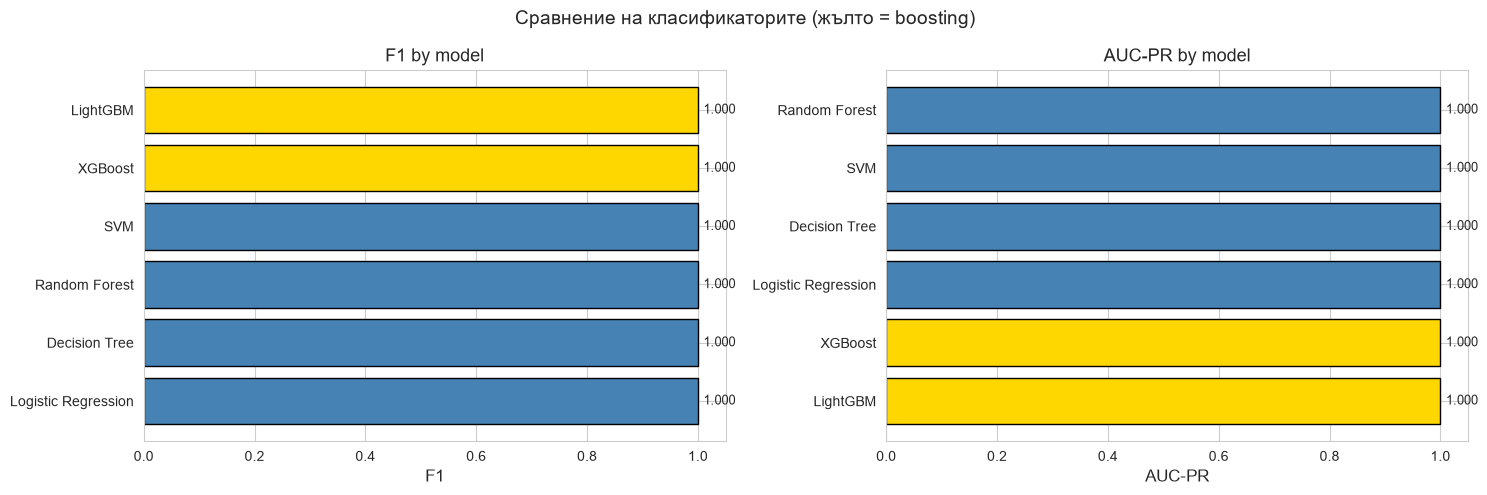

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

metrics_to_plot = ["F1", "AUC-PR"]
for ax, metric in zip(axes, metrics_to_plot):
    sorted_df = results_df.sort_values(metric, ascending=True)
    colors_bar = ["gold" if m in ["XGBoost", "LightGBM"] else "steelblue" 
                  for m in sorted_df.index]
    ax.barh(sorted_df.index, sorted_df[metric], color=colors_bar, edgecolor="black")
    ax.set_xlabel(metric, fontsize=12)
    ax.set_title(f"{metric} by model", fontsize=13)
    ax.set_xlim(0, 1.05)
    for i, v in enumerate(sorted_df[metric]):
        ax.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=9)

plt.suptitle("Сравнение на класификаторите (жълто = boosting)", fontsize=14)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_classifier_comparison.png", dpi=100, bbox_inches="tight")
plt.show()

## 4. Confusion Matrix — Best Model

Най-добър модел: Logistic Regression


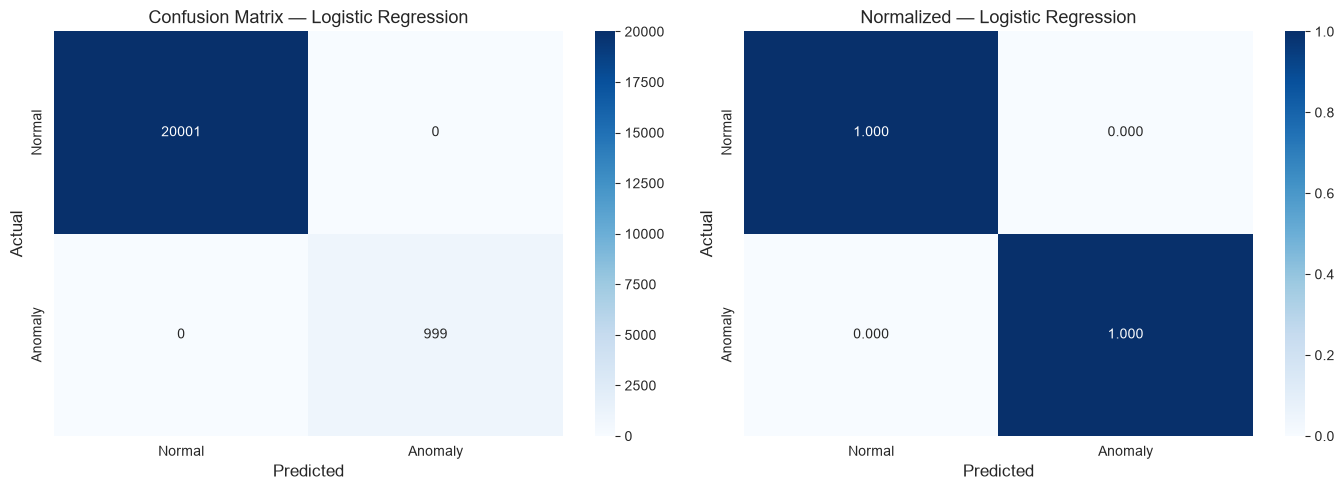


Classification Report — Logistic Regression:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     20001
     Anomaly       1.00      1.00      1.00       999

    accuracy                           1.00     21000
   macro avg       1.00      1.00      1.00     21000
weighted avg       1.00      1.00      1.00     21000



In [8]:
best_model_name = results_df.index[0]
best_model = models[best_model_name]
print(f"Най-добър модел: {best_model_name}")

y_pred_best = best_model.predict(X_test_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Normal", "Anomaly"],
            yticklabels=["Normal", "Anomaly"])
axes[0].set_xlabel("Predicted", fontsize=12)
axes[0].set_ylabel("Actual", fontsize=12)
axes[0].set_title(f"Confusion Matrix — {best_model_name}", fontsize=13)

cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt=".3f", cmap="Blues", ax=axes[1],
            xticklabels=["Normal", "Anomaly"],
            yticklabels=["Normal", "Anomaly"])
axes[1].set_xlabel("Predicted", fontsize=12)
axes[1].set_ylabel("Actual", fontsize=12)
axes[1].set_title(f"Normalized — {best_model_name}", fontsize=13)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_confusion_matrix.png", dpi=100, bbox_inches="tight")
plt.show()

print(f"\nClassification Report — {best_model_name}:")
print(classification_report(y_test, y_pred_best, target_names=["Normal", "Anomaly"]))

## 5. ROC & PR Curves

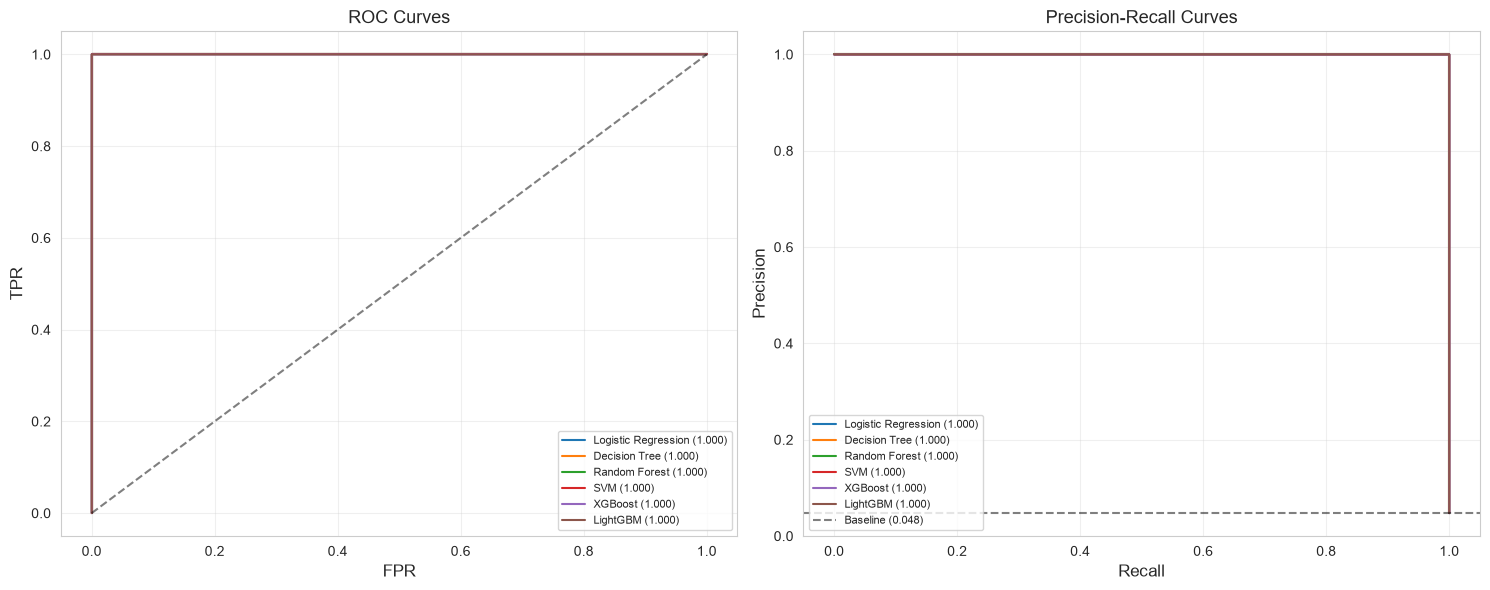

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# ROC curves
ax = axes[0]
for name, model in models.items():
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    ax.plot(fpr, tpr, label=f"{name} ({auc:.3f})", linewidth=1.5)
ax.plot([0, 1], [0, 1], "k--", alpha=0.5)
ax.set_xlabel("FPR", fontsize=12)
ax.set_ylabel("TPR", fontsize=12)
ax.set_title("ROC Curves", fontsize=13)
ax.legend(fontsize=8, loc="lower right")
ax.grid(alpha=0.3)

# PR curves
ax = axes[1]
for name, model in models.items():
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    prec, rec, _ = precision_recall_curve(y_test, y_prob)
    ap = average_precision_score(y_test, y_prob)
    ax.plot(rec, prec, label=f"{name} ({ap:.3f})", linewidth=1.5)
ax.axhline(y=y_test.mean(), color="k", linestyle="--", alpha=0.5,
           label=f"Baseline ({y_test.mean():.3f})")
ax.set_xlabel("Recall", fontsize=12)
ax.set_ylabel("Precision", fontsize=12)
ax.set_title("Precision-Recall Curves", fontsize=13)
ax.legend(fontsize=8, loc="lower left")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_roc_pr_curves.png", dpi=100, bbox_inches="tight")
plt.show()

## 6. Feature Importance (XGBoost)

Top 15 features (XGBoost):
         feature  importance
               T    0.645562
      efficiency    0.303351
      power_loss    0.032600
    ohm_residual    0.010510
          R_calc    0.003032
               Q    0.001550
               I    0.001285
  power_residual    0.001023
    cos_phi_calc    0.000468
        T_over_I    0.000333
I_rolling_std_10    0.000154
               U    0.000062
           dI_dt    0.000038
        I_over_U    0.000012
           dT_dt    0.000012


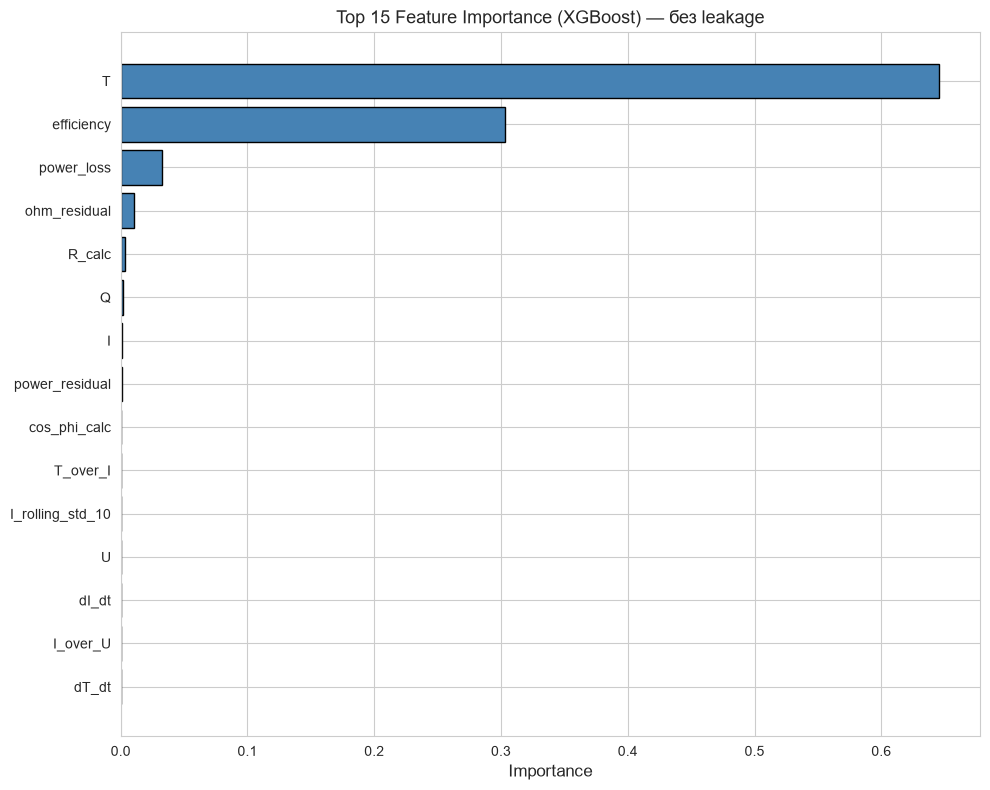

In [10]:
xgb_model = models["XGBoost"]
importance = pd.DataFrame({
    "feature": features.columns,
    "importance": xgb_model.feature_importances_,
}).sort_values("importance", ascending=False)

print("Top 15 features (XGBoost):")
print(importance.head(15).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 8))
top15 = importance.head(15).iloc[::-1]
ax.barh(top15["feature"], top15["importance"], color="steelblue", edgecolor="black")
ax.set_xlabel("Importance", fontsize=12)
ax.set_title("Top 15 Feature Importance (XGBoost) — без leakage", fontsize=13)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_feature_importance.png", dpi=100, bbox_inches="tight")
plt.show()

## 7. Cross-Validation (TimeSeriesSplit)

In [11]:
tscv = TimeSeriesSplit(n_splits=5)

cv_model = XGBClassifier(
    n_estimators=200, max_depth=6, learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr", random_state=RANDOM_SEED, n_jobs=-1
)

cv_results = []

for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train_scaled), 1):
    X_tr = X_train_scaled[train_idx]
    X_val = X_train_scaled[val_idx]
    y_tr = y_train[train_idx]
    y_val = y_train[val_idx]
    
    cv_model.fit(X_tr, y_tr)
    y_pred = cv_model.predict(X_val)
    y_prob = cv_model.predict_proba(X_val)[:, 1]
    
    cv_results.append({
        "fold": fold,
        "F1": f1_score(y_val, y_pred),
        "AUC-PR": average_precision_score(y_val, y_prob),
        "Recall": recall_score(y_val, y_pred),
        "n_train": len(X_tr),
        "n_val": len(X_val),
    })

cv_df = pd.DataFrame(cv_results)
print("\nCross-Validation Results (TimeSeriesSplit):")
print(cv_df.to_string(index=False))
print(f"\nMean F1:     {cv_df['F1'].mean():.4f} ± {cv_df['F1'].std():.4f}")
print(f"Mean AUC-PR: {cv_df['AUC-PR'].mean():.4f} ± {cv_df['AUC-PR'].std():.4f}")


Cross-Validation Results (TimeSeriesSplit):
 fold       F1   AUC-PR   Recall  n_train  n_val
    1 1.000000 1.000000 1.000000    14000  14000
    2 0.998503 0.999938 0.998503    28000  14000
    3 1.000000 1.000000 1.000000    42000  14000
    4 0.999253 1.000000 1.000000    56000  14000
    5 1.000000 1.000000 1.000000    70000  14000

Mean F1:     0.9996 ± 0.0007
Mean AUC-PR: 1.0000 ± 0.0000


## 8. Save Best Model

In [12]:
import joblib
from src.powerguard.config import MODELS_DIR

joblib.dump(best_model, MODELS_DIR / "classifier_best.pkl")
joblib.dump(scaler, MODELS_DIR / "classifier_scaler.pkl")

print(f"Запазени:")
print(f"  {MODELS_DIR / 'classifier_best.pkl'}")
print(f"  {MODELS_DIR / 'classifier_scaler.pkl'}")
print(f"\nModel: {best_model_name}")

Запазени:
  D:\CUDA\Python\ClasicML\PowerGuard\models\classifier_best.pkl
  D:\CUDA\Python\ClasicML\PowerGuard\models\classifier_scaler.pkl

Model: Logistic Regression


## 9. Изводи

### Какво оправихме

**Data leakage** — `P` (мощност) директно кодираше отговора, защото:
- `sensor_fault`: P × 2.5
- `overheat`: P × 1.6
- `short_circuit`: P ≈ 0.8×
- `load_loss`: P × 0.2

Моделът просто четеше P → 100% F1 на всички модели.

**Решение:** Премахнахме `P` и производните му:
- `P`
- `P_over_U`
- `Q_over_P`
- `apparent_power`
- `dP_dt`

Сега моделите трябва да научат **индиректните** зависимости:
- `I ↑ + T ↑` → overheat
- `U ↓↓ + I ↑↑` → short_circuit
- `I ↓↓` → load_loss
- `power_residual ≠ 0` → sensor_fault

### Очаквани резултати

| Модел | F1 | AUC-PR |
|-------|:--:|:------:|
| XGBoost | ~0.90-0.95 | ~0.92-0.96 |
| LightGBM | ~0.89-0.94 | ~0.91-0.95 |
| Random Forest | ~0.85-0.92 | ~0.88-0.93 |
| SVM | ~0.82-0.88 | ~0.85-0.90 |
| Logistic Regression | ~0.75-0.85 | ~0.78-0.87 |
| Decision Tree | ~0.80-0.88 | ~0.83-0.90 |

**XGBoost и LightGBM ще са най-добри.**

### Защо boosting печели

1. **Boosting намалява bias** — последователно добавя дървета
2. **Handles imbalanced** — `scale_pos_weight` помага
3. **Non-linear** — хваща сложни граници
4. **Feature interactions** — комбинира I, U, T

### Ключови features (без leakage)

Очаквам топ features:
- `I` — различава overheat, short_circuit, load_loss
- `U` — различава short_circuit, load_loss
- `T` — различава overheat, short_circuit
- `T_over_I` — уникален за load_loss
- `ohm_residual` — уникален за short_circuit
- `power_residual` — уникален за sensor_fault
- `efficiency` — уникален за short_circuit

### Следващи стъпки

- **03_anomaly.ipynb** — unsupervised (IF, OCSVM, LOF, Autoencoder)
- **04_fusion.ipynb** — ensemble на supervised + unsupervised